# QuSpin Kitaev chain defect operators

Created: 28-10-2026

# Imports

In [1]:
from quspin.operators import hamiltonian
from quspin.operators import quantum_operator
from quspin.basis import spinless_fermion_basis_1d
import numpy as np

In [2]:
import quimb.tensor as qtn
import quimb as qu

In [3]:
from pathlib import Path

# One source of truth for the system size and random initialization.
num_sites = 16
random_seed = 0

In [4]:
import matplotlib.pyplot as plt

In [5]:
from tqdm import tqdm

In [6]:
import pickle

# Analysis

## Find ground states

In [7]:
# Use periodic boundary conditions.
def get_kitaev_chain_hamiltonian(t, L=10):
    static = [
        ["+-", [[-t, i, (i+1)%L] for i in range(L)]],
        ["+-", [[-t, (i+1)%L, i] for i in range(L)]],
        ["--", [[t, i, (i+1)%L] for i in range(L)]],
        ["++", [[t, (i+1)%L, i] for i in range(L)]],
        ["I", [[(1-t)*(0.5), i] for i in range(L)]],
        ["+-", [[-(1-t), i, i] for i in range(L)]]
    ]

    basis = spinless_fermion_basis_1d(L, Nf=None)
    out = hamiltonian(
        static,
        [],
        basis=basis,
        dtype=np.float64,
        check_symm=False,
        check_herm=False
    )

    return out

In [8]:
parameters = np.linspace(0,1,201)

In [9]:
# Build one sparse Hamiltonian at a time; retaining all 201 is unnecessary.
assert num_sites >= 14, "The defect regions below require at least 14 sites."

In [10]:
energies = []
groundstates = []
eigenstate_residuals = []
rng = np.random.default_rng(random_seed)

for t in tqdm(parameters):
    h = get_kitaev_chain_hamiltonian(t, num_sites)
    # A fresh generic start can reach either fermion-parity sector.
    e, psi = h.eigsh(k=1, which='SA', tol=1e-11,
                     v0=rng.normal(size=h.Ns))
    energies.append(e[0])
    groundstates.append(psi[:, 0])
    eigenstate_residuals.append(np.linalg.norm(h.dot(psi[:, 0]) - e[0]*psi[:, 0]))
    del h

assert max(eigenstate_residuals) < 1e-8

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 201/201 [04:36<00:00,  1.37s/it]


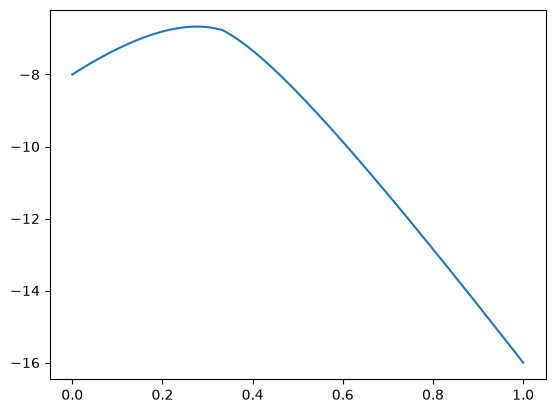

In [11]:
plt.plot(parameters, energies)

In [12]:
energies = np.array(energies)
parameters = np.array(parameters)

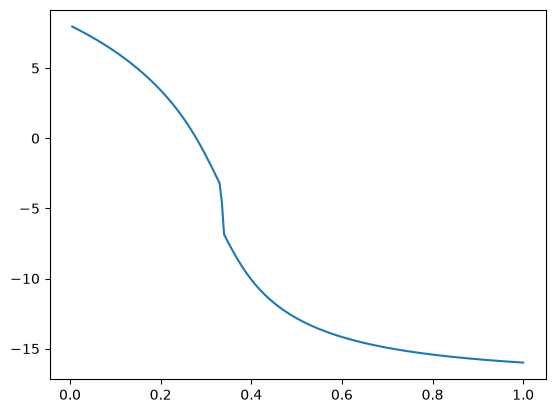

In [13]:
plt.plot(parameters[1:], (energies[1:] - energies[:-1])/(parameters[1]- parameters[0]))

## Expectations and correlation lengths

In [14]:
middle_site = num_sites//2

In [15]:
n_middle_site_op = quantum_operator(
    {"n": [["n", [[1, middle_site]]]]},
    basis=spinless_fermion_basis_1d(num_sites, Nf=None),
    dtype=np.complex128
)

Hermiticity check passed!
Symmetry checks passed!


In [16]:
n_middle_site_op.expt_value(groundstates[0])

np.complex128(0.9999999999999998+0j)

In [17]:
n_middle_site_exps = np.real_if_close([
    n_middle_site_op.expt_value(psi)
    for psi in groundstates
])

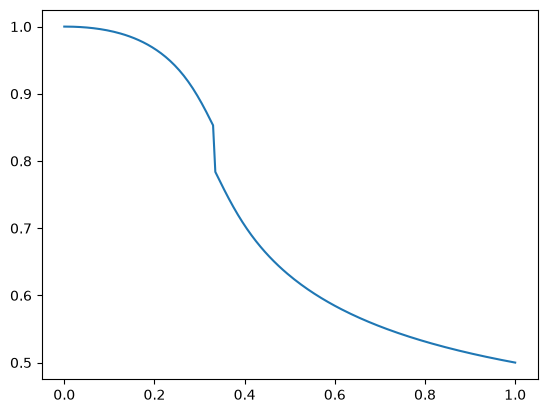

In [18]:
plt.plot(parameters, n_middle_site_exps)

In [19]:
n_site_ops = [
    quantum_operator(
        {"n": [["n", [[1, i]]]]},
        basis=spinless_fermion_basis_1d(num_sites, Nf=None),
        dtype=np.complex128,
        check_symm=False,
        check_herm=False
    )
    for i in range(num_sites)
]

In [20]:
n_site_exps = [
    [op.expt_value(psi) for psi in groundstates]
    for op in n_site_ops
]

In [21]:
n_site_exps = np.real_if_close(np.array(n_site_exps))

In [22]:
n_site_exps.shape

(16, 201)

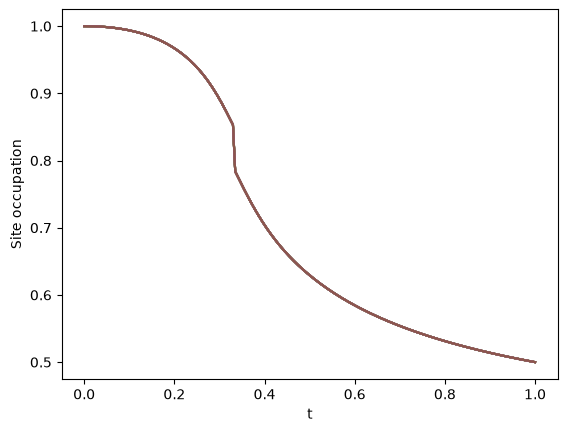

In [23]:
plt.plot(parameters, n_site_exps.T);
plt.xlabel("t");
plt.ylabel("Site occupation");

In [24]:
n_two_site_ops = [
    quantum_operator(
        {"n": [["nn", [[1, 0, i]]]]},
        basis=spinless_fermion_basis_1d(num_sites, Nf=None),
        dtype=np.complex128,
        check_symm=False,
        check_herm=False
    )
    for i in range(num_sites//2)
]

In [25]:
n_two_site_exps = np.real_if_close(np.array([
    [op.expt_value(psi) for psi in groundstates]
    for op in n_two_site_ops
]))

In [26]:
n_two_site_exps.shape

(8, 201)

In [27]:
n_site_exps.shape

(16, 201)

In [28]:
(n_site_exps[0]*n_site_exps[:(num_sites//2)]).shape

(8, 201)

In [29]:
n_correlations = np.real_if_close(
    n_two_site_exps - n_site_exps[0]*n_site_exps[:num_sites//2]
)
assert not np.iscomplexobj(n_correlations), "Unexpected imaginary density correlation."

# Signed/vanishing correlations do not have a real logarithm.
# Mask values at the numerical noise floor instead of manufacturing zeros.
correlation_atol = 1e-12

def log_correlation_magnitude(values, atol=correlation_atol):
    magnitude = np.abs(values)
    out = np.full(magnitude.shape, np.nan, dtype=float)
    np.log(magnitude, out=out, where=magnitude > atol)
    return out

def effective_correlation_length(correlations, r1, r2, atol=correlation_atol):
    """Two-point decay estimate; NaN when the magnitude does not resolve a decay.

    Assumes |C(r)| ~ A exp(-r/xi). Finite-ring and non-exponential
    corrections mean this is an effective estimate, not an asymptotic fit.
    """
    if not 0 <= r1 < r2 < len(correlations):
        raise ValueError("Require 0 <= r1 < r2 < number of separations.")
    a, b = np.abs(correlations[r1]), np.abs(correlations[r2])
    valid = (a > atol) & (b > atol) & (b < a)
    log_ratio = log_correlation_magnitude(b, atol) - log_correlation_magnitude(a, atol)
    out = np.full(np.shape(a), np.nan, dtype=float)
    np.divide(-(r2-r1), log_ratio, out=out, where=valid)
    return out

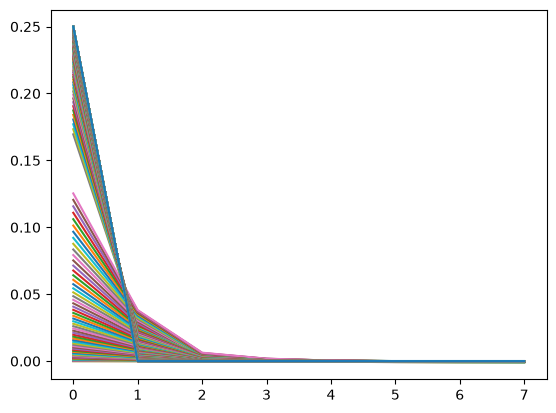

In [30]:
plt.plot(n_correlations);

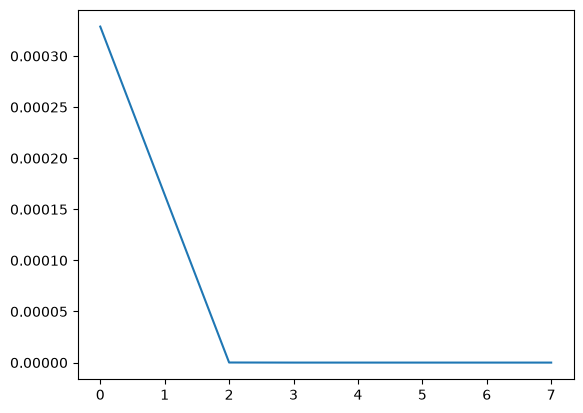

In [31]:
plt.plot(n_correlations[:,5]);

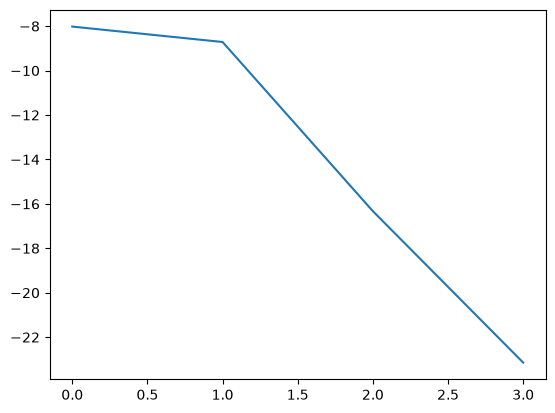

In [32]:
plt.plot(log_correlation_magnitude(n_correlations[:, 5]));

In [33]:
effective_correlation_length(n_correlations[:, 10], 0, 5)

array(nan)

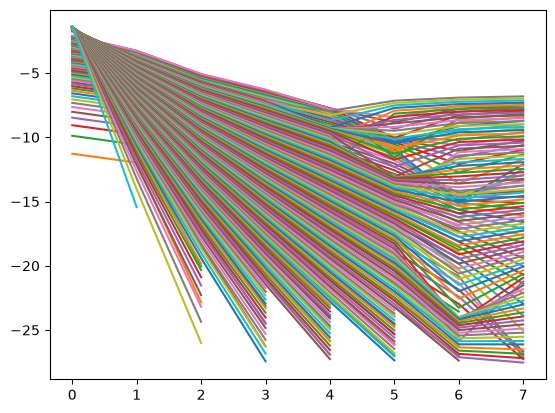

In [34]:
plt.plot(log_correlation_magnitude(n_correlations));

In [35]:
n_correlations.shape

(8, 201)

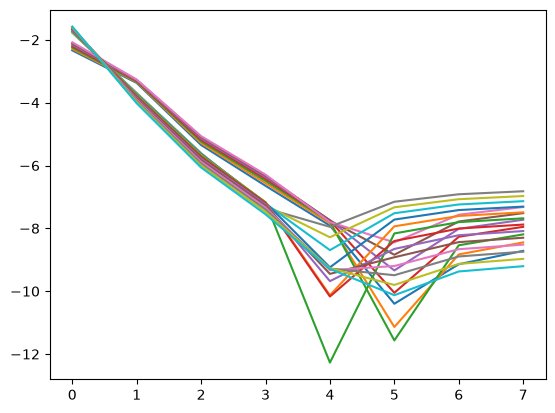

In [36]:
plt.plot(log_correlation_magnitude(n_correlations[:, 60:80]));

In [37]:
corr_lengths = effective_correlation_length(n_correlations, 1, 3)

In [38]:
np.count_nonzero(np.isfinite(corr_lengths))

np.int64(188)

In [39]:
# Unresolved estimates stay NaN; do not replace them with zero or huge finite values.

In [40]:
n_correlations.shape

(8, 201)

In [41]:
np.max(np.abs(np.imag(n_correlations)))

np.float64(0.0)

In [42]:
n_correlations = np.real(n_correlations)

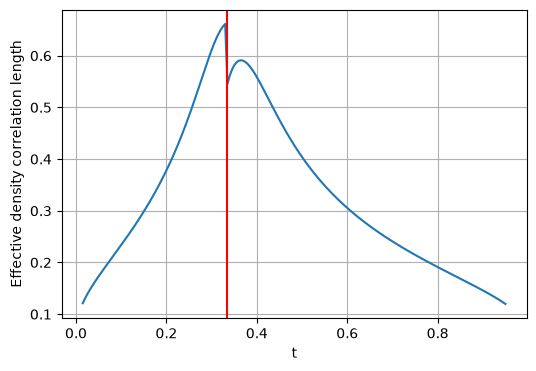

In [43]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(parameters, corr_lengths)
ax.axvline(1/3, color='red')
ax.set(xlabel="t", ylabel="Effective density correlation length")
ax.grid()

## Defect operators

In [44]:
symmetry_sites = list(range(5, 11))
left_defect_sites = [3, 4]
right_defect_sites = [11, 12]
all_defect_sites = left_defect_sites + right_defect_sites
# QuSpin sorts sub_sys_A by default. Make that ordering explicit.
retained_sites = sorted(all_defect_sites + symmetry_sites)
rdm_symmetry_sites = [retained_sites.index(i) for i in symmetry_sites]
assert retained_sites == left_defect_sites + symmetry_sites + right_defect_sites

num_symmetry_sites = len(symmetry_sites)
num_defect_sites = len(all_defect_sites)
num_symmetry_and_defect_sites = len(retained_sites)

In [45]:
basis = spinless_fermion_basis_1d(num_sites, Nf=None)
symmetry_and_defect_basis = spinless_fermion_basis_1d(num_symmetry_and_defect_sites, Nf=None)

In [46]:
# z = n - 1/2, so physical parity prod(1 - 2*n) = prod(-2*z).
symmetry_op = quantum_operator(
    {"fp": [["z"*num_symmetry_sites,
              [[(-2)**num_symmetry_sites, *rdm_symmetry_sites]]]]},
    basis=symmetry_and_defect_basis,
    dtype=np.complex128
)

defect_basis = spinless_fermion_basis_1d(num_defect_sites, Nf=None)
fp_matrix = np.diag([1, -1, -1, 1])

Hermiticity check passed!
Symmetry checks passed!


In [47]:
def get_defect_operator_from_one_sided_environment_matrix(E):
    U, S, Vh = np.linalg.svd(E)
    return ((U @ Vh).conj().T, np.sum(S))

In [48]:
all_defect_sites + symmetry_sites

[3, 4, 11, 12, 5, 6, 7, 8, 9, 10]

In [49]:
def get_defect_operators(edm, num_iters=20, seed=random_seed):
    """Alternate unitary polar updates to maximize |Tr((L tensor R) E)|.

    This is a local alternating optimization, not a global optimality proof.
    Explicit index order makes updates independent of tensor storage order.
    """
    if num_iters < 1:
        raise ValueError("num_iters must be positive")
    scores = []
    rng = np.random.default_rng(seed)
    dl, dr = edm.ind_size('kl1'), edm.ind_size('kr2')
    if edm.ind_size('bl1') != dl or edm.ind_size('br2') != dr:
        raise ValueError("Each defect environment must be square")
    initial = rng.normal(size=(dl, dl)) + 1j*rng.normal(size=(dl, dl))
    # The initial defect must also be unitary for scores to be bounded by 1.
    left_defect_op = qtn.Tensor(np.linalg.qr(initial)[0], inds=['kl1', 'bl1'])

    for _ in range(num_iters):
        right_edm = (edm & left_defect_op.reindex(
            {'kl1': 'bl1', 'bl1': 'kl1'})).contract()
        data = right_edm.transpose('kr2', 'br2').data
        sol, score = get_defect_operator_from_one_sided_environment_matrix(data)
        right_defect_op = qtn.Tensor(sol, inds=['kr2', 'br2'])
        scores.append(score)

        left_edm = (edm & right_defect_op.reindex(
            {'kr2': 'br2', 'br2': 'kr2'})).contract()
        data = left_edm.transpose('kl1', 'bl1').data
        sol, score = get_defect_operator_from_one_sided_environment_matrix(data)
        left_defect_op = qtn.Tensor(sol, inds=['kl1', 'bl1'])
        scores.append(score)

    return (left_defect_op, right_defect_op), scores

In [50]:
x = qtn.Tensor(data=np.array([[1,2], [3,4]]), inds=['k', 'b'])

In [51]:
x.data

array([[1, 2],
       [3, 4]])

In [52]:
def extract_n1(psi):
    rho = basis.partial_trace(
        psi,
        sub_sys_A=retained_sites,
        subsys_ordering=True,
        return_rdm="A",
        enforce_pure=True
    )

    edm = symmetry_and_defect_basis.partial_trace(
        symmetry_op.matmat(rho),
        sub_sys_A=rdm_symmetry_sites,
        return_rdm='B'
    )
    # QuSpin 1.0.1 returns a singleton batch axis for a mixed input.
    edm = np.asarray(edm).reshape(2**num_defect_sites, 2**num_defect_sites)
    
    # Each boundary contains two sites.
    # Choice of ind names come from get_defect_operators function.
    dl, dr = 2**len(left_defect_sites), 2**len(right_defect_sites)
    reshaped_edm = edm.reshape(dl, dr, dl, dr)
    qtn_edm = qtn.Tensor(
        reshaped_edm,
        inds= ['kl1', 'kr2', 'bl1', 'br2']
    )

    (left_defect_op, right_defect_op), scores = get_defect_operators(qtn_edm)

    right_defect_op = (
        right_defect_op
        .transpose('kr2', 'br2')
        .data
    )

    left_defect_op = (
        left_defect_op
        .transpose('kl1', 'bl1')
        .data
    )

    rho_r = basis.partial_trace(
        psi,
        sub_sys_A=right_defect_sites,
        return_rdm="A",
        enforce_pure=True
    )
    
    right_index = np.trace(
        (right_defect_op.T.conj())
        @ fp_matrix
        @ right_defect_op
        @ fp_matrix
        @ rho_r
    )

    rho_l = basis.partial_trace(
        psi,
        sub_sys_A=left_defect_sites,
        return_rdm="A",
        enforce_pure=True
    )
    
    left_index = np.trace(
        (left_defect_op.T.conj())
        @ fp_matrix
        @ left_defect_op
        @ fp_matrix
        @ rho_l
    )
    
    out = [
        left_index,
        right_index,
        scores
    ]

    return out

In [53]:
results = list()

for psi in tqdm(groundstates):
    results.append(extract_n1(psi))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 201/201 [00:29<00:00,  6.77it/s]


In [54]:
indices_array = np.array([l[:2] for l in results])

In [55]:
np.max(np.abs(np.imag(indices_array[:, :2])))

np.float64(1.4421502787565011e-15)

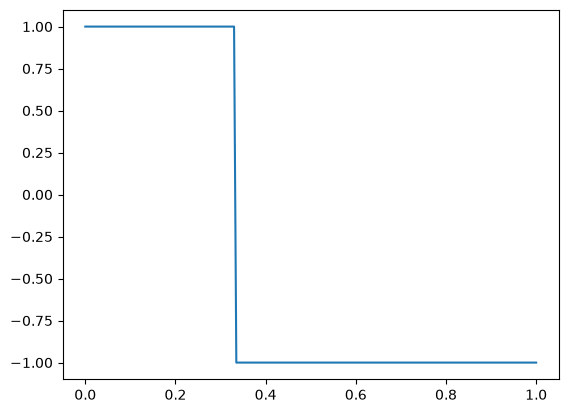

In [56]:
plt.plot(parameters, np.real(indices_array[:, 0]))

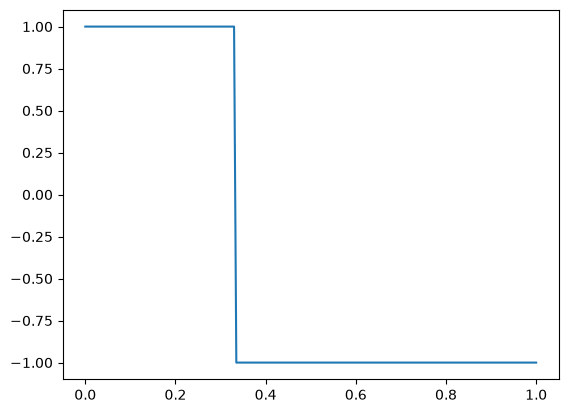

In [57]:
plt.plot(parameters, np.real(indices_array[:, 1]))

In [58]:
scores_array = np.array([l[2][-1] for l in results])

(-0.05, 1.05)

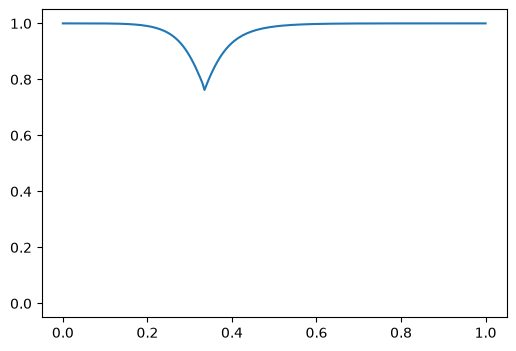

In [59]:
fig, ax = plt.subplots(figsize=(6,4))

ax.plot(parameters, np.real(scores_array))
ax.set_ylim(-0.05, 1.05)

## Save results

In [60]:
# Assemble results before inspecting their shape.

In [61]:
all_results = np.concatenate(
    [np.real(indices_array), scores_array[:, np.newaxis]],
    axis=1
)
assert all_results.shape == (len(parameters), 3)
all_results.shape

(201, 3)

In [62]:
# Locate code/ from either the notebook directory or another directory in the repo.
code_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "fermionic_cases" / "kitaev_chain").is_dir()), None)
if code_dir is None:
    raise FileNotFoundError("Run this notebook from within the repository's code/ directory.")
results_path = code_dir / "make_plots/data/kitaev_chain_defect_operators/results.pkl"
results_path.parent.mkdir(parents=True, exist_ok=True)
with results_path.open('wb') as f:
    pickle.dump(all_results, f)

# Interpretation and numerical limits

The two columns of parity indices should approach +1 in the trivial limit
(t = 0) and -1 in the topological limit (t = 1); the third column is the
optimized defect overlap. The Hamiltonian uses physical periodic fermionic
boundary conditions. The bulk gap closes at t = 1/3; a finite system can have
degenerate ground states there, so a single eigensolver vector need not give
a unique index at the transition.

The density correlation length is a two-separation effective estimate. NaN
means the decay was unresolved or not decreasing; it does not mean zero
correlation length. Alternating unitary optimization is local and can depend
on initialization. Its seed is fixed here for reproducibility.

QuSpin's fermionic partial trace includes reordering signs; replacing it with
an ordinary tensor trace changes the disconnected-subsystem convention.
See [QuSpin partial-trace documentation](https://quspin.github.io/QuSpin/generated/quspin.basis.spinless_fermion_basis_1d.html).
The parity-string normalization now uses prod(1-2n); the former overall minus
sign changed the environment phase, not the optimized overlap or parity index.

# Legacy Schmidt-factor approximation (not used in the sweep)

In [63]:
def extract_n1_schmidt_legacy(psi):
    rho = basis.partial_trace(
        psi,
        sub_sys_A=all_defect_sites+symmetry_sites,
        return_rdm="A",
        enforce_pure=True
    )

    edm = symmetry_and_defect_basis.partial_trace(
        symmetry_op.matmat(rho),
        sub_sys_A=rdm_symmetry_sites,
        return_rdm='B'
    )
    edm = np.asarray(edm).reshape(2**num_defect_sites, 2**num_defect_sites)
    
    # Hard code warming.
    reshaped_edm = edm.reshape(4,4,4,4)
    left_right_edm = np.transpose(reshaped_edm, axes=(0, 2, 1, 3))
    reshaped_left_right_edm = left_right_edm.reshape(16, 16)

    left_edm, left_right_schmidt_values, right_edm = (
        np.linalg.svd(reshaped_left_right_edm)
    )

    left_edm = left_edm[:, 0].reshape(4,4)
    left_defect_op, left_score = (
        get_defect_operator_from_one_sided_environment_matrix(left_edm)
    )

    rho_l = basis.partial_trace(
        psi,
        sub_sys_A=left_defect_sites,
        return_rdm="A",
        enforce_pure=True
    )

    left_index = np.trace(
        (left_defect_op.T.conj())
        @ fp_matrix
        @ left_defect_op
        @ fp_matrix
        @ rho_l
    )

    right_edm = right_edm[0].reshape(4,4)

    right_defect_op, right_score = (
        get_defect_operator_from_one_sided_environment_matrix(right_edm)
    )

    rho_r = basis.partial_trace(
        psi,
        sub_sys_A=right_defect_sites,
        return_rdm="A",
        enforce_pure=True
    )
    
    right_index = np.trace(
        (right_defect_op.T.conj())
        @ fp_matrix
        @ right_defect_op
        @ fp_matrix
        @ rho_r
    )

    score = np.trace(
        np.kron(left_defect_op, right_defect_op) @ edm
    )
    score = np.abs(score)

    out = [
        left_right_schmidt_values,
        left_index,
        right_index,
        score
    ]

    return out